#1.Library Import:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
warnings.filterwarnings("ignore")

#2. Data Loading & Cleaning:

In [8]:
df = pd.read_csv("/content/Customers report.csv")
print(df.head())
df["internet_service"]= df["internet_service"].fillna("unknown")


   gender  senior_citizen  tenure_months        contract internet_service  \
0    Male               0              7        One year              NaN   
1    Male               0             56        One year              DSL   
2  Female               0             48  Month-to-month            Fiber   
3    Male               0             32        One year              NaN   
4  Female               1             32        One year              NaN   

   support_calls  monthly_charges  total_charges  churn  
0              2            94.07         658.49      0  
1              3            51.88        2905.28      0  
2              6            48.66        2335.68      0  
3              1            81.49        2607.68      0  
4              5            94.71        3030.72      0  


In [9]:
X = df.drop(columns=["churn"])
y = df["churn"]

#3.Categorical & Numerical Columns Separation:

In [10]:
categorical_cols =["gender", "contract", "internet_service"]
numerical_cols = ["senior_citizen", "tenure_months", "support_calls", "monthly_charges", "total_charges"]


#4.Preprocessing Pipeline:

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

#5.Train Test Split:

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)


#6.ANN Binary Classification:

In [13]:
model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3), #ignoring overfit
    Dense(32, activation="relu", ),
    Dense(1, activation="sigmoid")

])


#7.Model Compilation:

In [14]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

#8.Model Training:

In [15]:
history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2)
print("\n--- Customer Churn ANN Model Training Completed Successfully! ----")

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7839 - loss: 0.5054 - val_accuracy: 0.8396 - val_loss: 0.3906
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8292 - loss: 0.3979 - val_accuracy: 0.8500 - val_loss: 0.3529
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8406 - loss: 0.3706 - val_accuracy: 0.8604 - val_loss: 0.3371
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8453 - loss: 0.3675 - val_accuracy: 0.8604 - val_loss: 0.3327
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8516 - loss: 0.3606 - val_accuracy: 0.8604 - val_loss: 0.3300
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8495 - loss: 0.3526 - val_accuracy: 0.8646 - val_loss: 0.3305
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8521 - loss: 0.3542 - val_accuracy: 0.8604 - val_loss: 0.3276
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8448 - loss: 0.3521 - val_accuracy: 0.8687 - val_loss:

#9.Model Evaluation:

In [18]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8567 - loss: 0.3320 
Test Loss: 0.33203133940696716
Test Accuracy: 0.8566666841506958


# #10.Model Training & Validation Graphs

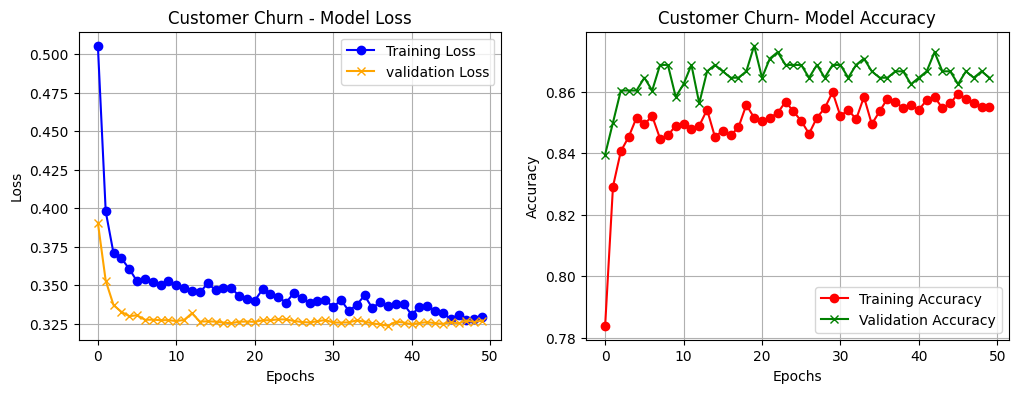

In [19]:
plt.figure(figsize=(12,4))

#1. Loss Graph
plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Training Loss", color="blue", marker="o")
plt.plot(history.history["val_loss"], label="validation Loss", color="orange", marker="x")
plt.title("Customer Churn - Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

#2. Accuracy Graph
plt.subplot(1,2,2)
plt.plot(history.history["accuracy"], label="Training Accuracy", color="red", marker="o")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy", color="green", marker="x")
plt.title("Customer Churn- Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()